# Acquire climate data

Download ERA5-Land hourly precipitation and 2 m temperature for every 0.1° grid point in the study region, as configured in `configs/climate.yaml` (`region_lat`, `region_lon`), in a single request to the Copernicus Climate Data Store. Each study site is then assigned to the cell containing its centroid, unless `site_cell_overrides` names a different cell. Raw files are cached under `outputs/climate/raw/region/` and reused on later runs. Credentials are read from `~/.cdsapirc`.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

from cds_pull import ClimateConfig, ClimateDownloader, assign_cells, cell_table, load_sites, open_region
from cds_pull.cells import cells_geodataframe, write_cells_gpkg
from cds_pull.checks import check_region_grid, check_site_cells
from cds_pull.plotting import plot_cells_map, save_figure

ROOT = Path.cwd().parent
assert (ROOT / "pyproject.toml").exists(), "Run notebooks from the notebooks/ folder"

## Climate configuration

In [2]:
config = ClimateConfig.from_yaml(ROOT / "configs" / "climate.yaml", project_root=ROOT)
config.to_dict()

{'sites_source': '/home/tshihadah/code/wadi-gaza-research/sites/StudySites.gpkg',
 'id_field': 'site_name',
 'output_dir': '/home/tshihadah/code/wadi-gaza-research/outputs/climate',
 'dataset': 'reanalysis-era5-land-timeseries',
 'variables': ('2m_temperature', 'total_precipitation'),
 'region_lat': (31.2, 32.0),
 'region_lon': (34.2, 34.8),
 'site_cell_overrides': {'HolotPalmahim': 'N31.9_E34.8',
  'NahalRubin': 'N31.9_E34.8'},
 'extraction_range': ['1990-10-01', '2025-12-31'],
 'reference_period': (1991, 2020),
 'study_years': (2019, 2025),
 'study_months': (1, 5, 9, 11),
 'wet_season_months': (10, 4),
 'near_zero_normal_mm': 10,
 'min_reference_periods': 30,
 'daily_temp_range_c': (-5, 45),
 'daily_precip_cap_mm': 200}

## Download the region

One NetCDF request covers the whole region (a CSV area request exceeds the CDS size limit). The cached download is reused; pass `force=True` to re-download. The returned grid is checked against the configured region.

In [3]:
downloader = ClimateDownloader(config)
record = downloader.download()
pd.Series(record)

dataset                                reanalysis-era5-land-timeseries
request              {"area": [32.05, 34.15, 31.15, 34.85], "data_f...
area                                      [32.05, 34.15, 31.15, 34.85]
date_range                                       1990-10-01/2026-01-01
n_cells                                                             63
n_cells_with_data                                                   36
downloaded_utc                               2026-10-26T22:34:54+00:00
cdsapi_version                                                   0.7.7
raw_path                                         raw/region/region.zip
sha256               a72c7ac30bf2892c9af0474f5ac245d0ee83a436be300b...
files                reanalysis-era5-land-timeseries-sfc-2m-tempera...
dtype: object

## Region grid

ERA5-Land has values only at grid points it treats as land. Points treated as sea are present in the file but empty.

In [4]:
cells = cell_table(open_region(downloader.raw_dir))
print(f"{len(cells)} grid points, {int(cells['has_data'].sum())} with data")
cells.pivot(index="cell_lat", columns="cell_lon", values="has_data").sort_index(ascending=False).astype(int)

63 grid points, 36 with data


cell_lon,34.2,34.3,34.4,34.5,34.6,34.7,34.8
cell_lat,,,,,,,
32.0,0,0,0,0,0,1,1
31.9,0,0,0,0,0,0,1
31.8,0,0,0,0,0,1,1
31.7,0,0,0,0,1,1,1
31.6,0,0,0,1,1,1,1
31.5,0,0,1,1,1,1,1
31.4,0,0,1,1,1,1,1
31.3,1,1,1,1,1,1,1
31.2,1,1,1,1,1,1,1


## Assign sites to cells

Each site uses the cell containing its polygon centroid (`assignment = "centroid"`). Sites listed in `site_cell_overrides` use the named cell instead (`assignment = "manual"`). Holot Palmahim and Nahal Rubin share a centroid cell (N31.9_E34.7) that ERA5-Land treats as sea, so both are assigned to the adjacent cell to the east (N31.9_E34.8).

In [5]:
sites = load_sites(config.sites_source, config.id_field)
site_cells = assign_cells(sites, config.id_field, config.site_cell_overrides)
config.output_dir.mkdir(parents=True, exist_ok=True)
site_cells.to_csv(config.output_dir / "site_cells.csv", index=False)
site_cells

,site,centroid_lat,centroid_lon,centroid_cell_id,cell_id,cell_lat,cell_lon,distance_km,assignment,shared_with
0,AlAhrashProtectorate,31.302993,34.219816,N31.3_E34.2,N31.3_E34.2,31.3,34.2,1.911955,centroid,
1,BesorStream,31.357033,34.469869,N31.4_E34.5,N31.4_E34.5,31.4,34.5,5.568553,centroid,
2,HaBesorNationalPark,31.283299,34.493092,N31.3_E34.5,N31.3_E34.5,31.3,34.5,1.969611,centroid,
3,HolotNizzanim,31.745869,34.618380,N31.7_E34.6,N31.7_E34.6,31.7,34.6,5.388516,centroid,
4,HolotPalmahim,31.915304,34.725573,N31.9_E34.7,N31.9_E34.8,31.9,34.8,7.228584,manual,NahalRubin
5,NahalRubin,31.938234,34.719577,N31.9_E34.7,N31.9_E34.8,31.9,34.8,8.699998,manual,HolotPalmahim
6,WadiGaza,31.452693,34.404336,N31.5_E34.4,N31.5_E34.4,31.5,34.4,5.276332,centroid,


## Cell reference layer

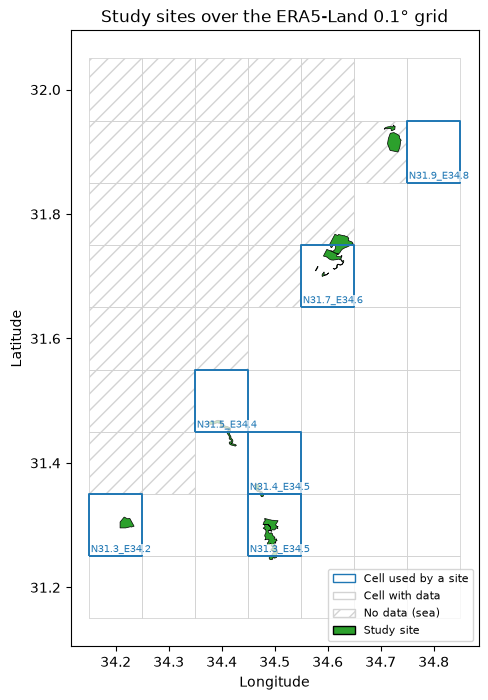

In [6]:
cells["used"] = cells["cell_id"].isin(site_cells["cell_id"])
write_cells_gpkg(cells, config.output_dir / "era5land_cells.gpkg")
fig, ax = plot_cells_map(sites, cells_geodataframe(cells))
save_figure(fig, config.output_dir / "plots" / "sites_over_cells.png")
plt.show()

## Confirm the grid and site cells

In [7]:
cell_checks = pd.DataFrame(check_region_grid(cells, config) + check_site_cells(site_cells, cells))
display(cell_checks)
if not cell_checks["passed"].all():
    raise RuntimeError("At least one grid or site-cell check failed; inspect the table above.")

,check,scope,passed,detail
0,region_grid,all,True,"63 grid points, 36 with data"
1,site_cell_has_data,AlAhrashProtectorate,True,N31.3_E34.2 (centroid)
2,site_cell_has_data,BesorStream,True,N31.4_E34.5 (centroid)
3,site_cell_has_data,HaBesorNationalPark,True,N31.3_E34.5 (centroid)
4,site_cell_has_data,HolotNizzanim,True,N31.7_E34.6 (centroid)
5,site_cell_has_data,HolotPalmahim,True,"N31.9_E34.8 (manual, centroid cell N31.9_E34.7)"
6,site_cell_has_data,NahalRubin,True,"N31.9_E34.8 (manual, centroid cell N31.9_E34.7)"
7,site_cell_has_data,WadiGaza,True,N31.5_E34.4 (centroid)
